In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Check Runtime settings.")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Campus_Threat")

FIGHTING_DIR = PROJECT / "Fighting"
NORMAL_DIR = PROJECT / "Normal_Videos_for_Event_Recognition"
METADATA_DIR = PROJECT / "metadata"

print("Fighting videos:", len(list(FIGHTING_DIR.glob("*.mp4"))))
print("Normal videos:", len(list(NORMAL_DIR.glob("*.mp4"))))

print("Metadata files:")
for file in METADATA_DIR.iterdir():
    print(file.name)

Fighting videos: 50
Normal videos: 50
Metadata files:
split_manifest.csv
fighting_intervals.csv
fighting_review_status.csv


In [ ]:
import pandas as pd

manifest = pd.read_csv(METADATA_DIR / "split_manifest.csv")
intervals = pd.read_csv(METADATA_DIR / "fighting_intervals.csv")

print("========== MANIFEST ==========")

print("\nColumn names:")
print(manifest.columns.tolist())

print("\nFirst 5 rows:")
display(manifest.head())

print("\nVideos by split and category:")
print(pd.crosstab(manifest["split"], manifest["category"]))

print("\n========== FIGHTING INTERVALS ==========")

print("\nColumn names:")
print(intervals.columns.tolist())

print("\nFirst 5 rows:")
display(intervals.head())

print("\nIntervals by split:")
print(intervals.groupby("split").size())

========== MANIFEST ==========

Column names:
['original_video_id', 'filename', 'original_video_path', 'category', 'label', 'class_name', 'source_split', 'line_number', 'official_fold', 'split']

First 5 rows:


,original_video_id,filename,original_video_path,category,label,class_name,source_split,line_number,official_fold,split
0,Fighting038_x264,Fighting038_x264.mp4,C:\Users\KIIT0001\OneDrive\Desktop\Campus_thre...,Fighting,1,VIOLENCE,train_001.txt,253,fold_001,train
1,Fighting029_x264,Fighting029_x264.mp4,C:\Users\KIIT0001\OneDrive\Desktop\Campus_thre...,Fighting,1,VIOLENCE,train_001.txt,244,fold_001,train
2,Fighting031_x264,Fighting031_x264.mp4,C:\Users\KIIT0001\OneDrive\Desktop\Campus_thre...,Fighting,1,VIOLENCE,train_001.txt,246,fold_001,train
3,Fighting022_x264,Fighting022_x264.mp4,C:\Users\KIIT0001\OneDrive\Desktop\Campus_thre...,Fighting,1,VIOLENCE,train_001.txt,237,fold_001,train
4,Fighting030_x264,Fighting030_x264.mp4,C:\Users\KIIT0001\OneDrive\Desktop\Campus_thre...,Fighting,1,VIOLENCE,train_001.txt,245,fold_001,train



Videos by split and category:
category    Fighting  Normal_Videos_event
split                                    
test              12                   12
train             30                   30
validation         8                    8

========== FIGHTING INTERVALS ==========

Column names:
['video_id', 'filename', 'split', 'start_frame', 'end_frame', 'start_seconds', 'end_seconds', 'annotation_date']

First 5 rows:


,video_id,filename,split,start_frame,end_frame,start_seconds,end_seconds,annotation_date
0,Fighting003_x264,Fighting003_x264.mp4,test,1851,3039,61.700,101.3,2026-11-07T03:21:42
1,Fighting004_x264,Fighting004_x264.mp4,test,163,1245,5.433,41.5,2026-11-07T03:22:48
2,Fighting004_x264,Fighting004_x264.mp4,test,1771,2145,59.033,71.5,2026-11-07T03:23:30
3,Fighting004_x264,Fighting004_x264.mp4,test,3225,3411,107.500,113.7,2026-11-07T03:24:29
4,Fighting004_x264,Fighting004_x264.mp4,test,5037,5586,167.900,186.2,2026-11-07T03:25:47



Intervals by split:
split
test          36
train         64
validation    16
dtype: int64


In [ ]:
import cv2
import pandas as pd
from pathlib import Path

manifest = pd.read_csv(METADATA_DIR / "split_manifest.csv")
intervals = pd.read_csv(METADATA_DIR / "fighting_intervals.csv")

# Map each category to its Google Drive folder
def get_video_path(row):
    if row["category"] == "Fighting":
        return FIGHTING_DIR / row["filename"]
    elif row["category"] == "Normal_Videos_event":
        return NORMAL_DIR / row["filename"]
    else:
        return None

manifest["drive_path"] = manifest.apply(get_video_path, axis=1)

print("Missing videos:")
missing = manifest[
    ~manifest["drive_path"].apply(
        lambda p: p is not None and p.exists()
    )
]
print(missing[["filename", "category"]])

print("\nTotal missing:", len(missing))

# Validate fighting interval durations
intervals["duration_seconds"] = (
    intervals["end_seconds"] - intervals["start_seconds"]
)

print("\nFighting interval duration statistics:")
print(intervals["duration_seconds"].describe())

print("\nIntervals shorter than 2 seconds:",
      (intervals["duration_seconds"] < 2).sum())

print("\nIntervals at least 2 seconds:",
      (intervals["duration_seconds"] >= 2).sum())

Missing videos:
Empty DataFrame
Columns: [filename, category]
Index: []

Total missing: 0

Fighting interval duration statistics:
count    116.000000
mean      18.611241
std       17.236174
min        1.433000
25%        7.366750
50%       14.716500
75%       26.467000
max      117.067000
Name: duration_seconds, dtype: float64

Intervals shorter than 2 seconds: 2

Intervals at least 2 seconds: 114


In [ ]:
!pip install -q opencv-python-headless pandas numpy tqdm

In [ ]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import random
import shutil

# -----------------------------
# CONFIGURATION
# -----------------------------

SEED = 42
FRAMES_PER_CLIP = 16
SAMPLE_FPS = 8
CLIP_DURATION = 2.0
IMAGE_SIZE = 112
MAX_CLIPS_PER_VIDEO = 3

random.seed(SEED)
np.random.seed(SEED)

# Save extracted clips temporarily on Colab storage
OUTPUT_DIR = Path("/content/campus_clips")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(METADATA_DIR / "split_manifest.csv")
intervals = pd.read_csv(METADATA_DIR / "fighting_intervals.csv")

# -----------------------------
# VIDEO PATH MAPPING
# -----------------------------

def get_video_path(row):

    if row["category"] == "Fighting":
        return FIGHTING_DIR / row["filename"]

    elif row["category"] == "Normal_Videos_event":
        return NORMAL_DIR / row["filename"]

    raise ValueError(f"Unknown category: {row['category']}")


manifest["drive_path"] = manifest.apply(get_video_path, axis=1)

# -----------------------------
# EXTRACT ONE CLIP
# -----------------------------

def extract_clip(cap, start_seconds, fps):

    frame_indices = [
        int(round((start_seconds + i / SAMPLE_FPS) * fps))
        for i in range(FRAMES_PER_CLIP)
    ]

    frames = []

    for frame_idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
        ret, frame = cap.read()

        if not ret:
            return None

        frame = cv2.resize(
            frame,
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(frame)

    return np.stack(frames).astype(np.uint8)


# -----------------------------
# BUILD FIGHTING CLIP CANDIDATES
# -----------------------------

def get_fighting_starts(video_intervals):

    candidates = []

    for _, interval in video_intervals.iterrows():

        start = float(interval["start_seconds"])
        end = float(interval["end_seconds"])

        latest_start = end - CLIP_DURATION

        if latest_start < start:
            continue

        # Non-overlapping candidate windows
        current = start

        while current <= latest_start + 1e-6:
            candidates.append(round(current, 4))
            current += CLIP_DURATION

    # Select up to 3 evenly distributed candidate windows
    if len(candidates) > MAX_CLIPS_PER_VIDEO:

        selected_indices = np.linspace(
            0,
            len(candidates) - 1,
            MAX_CLIPS_PER_VIDEO,
            dtype=int
        )

        candidates = [candidates[i] for i in selected_indices]

    return candidates


# -----------------------------
# BUILD NORMAL CLIP CANDIDATES
# -----------------------------

def get_normal_starts(duration):

    latest_start = duration - CLIP_DURATION

    if latest_start <= 0:
        return []

    # Sample from different parts of the video
    fractions = [0.15, 0.50, 0.80]

    return [
        round(f * latest_start, 4)
        for f in fractions[:MAX_CLIPS_PER_VIDEO]
    ]


# -----------------------------
# EXTRACT ALL CLIPS
# -----------------------------

records = []

for _, row in tqdm(
    manifest.iterrows(),
    total=len(manifest),
    desc="Processing videos"
):

    video_path = Path(row["drive_path"])

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print("Could not open:", video_path)
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)

    if fps <= 0 or frame_count <= 0:
        cap.release()
        continue

    duration = frame_count / fps

    if row["category"] == "Fighting":

        video_intervals = intervals[
            intervals["video_id"] == row["original_video_id"]
        ]

        starts = get_fighting_starts(video_intervals)
        label = 1
        class_name = "VIOLENCE"

    else:

        starts = get_normal_starts(duration)
        label = 0
        class_name = "NON_VIOLENCE"

    for clip_number, start_seconds in enumerate(starts):

        # Make sure the clip is inside the source video
        if start_seconds + CLIP_DURATION > duration:
            continue

        clip = extract_clip(cap, start_seconds, fps)

        if clip is None:
            continue

        clip_id = (
            f"{row['split']}_"
            f"{row['original_video_id']}_"
            f"{class_name}_{clip_number:02d}"
        )

        clip_id = clip_id.replace("/", "_").replace("\\", "_")

        save_dir = OUTPUT_DIR / row["split"] / class_name
        save_dir.mkdir(parents=True, exist_ok=True)

        save_path = save_dir / f"{clip_id}.npy"

        np.save(save_path, clip)

        records.append({
            "clip_id": clip_id,
            "clip_path": str(save_path),
            "video_id": row["original_video_id"],
            "filename": row["filename"],
            "split": row["split"],
            "label": label,
            "class_name": class_name,
            "start_seconds": start_seconds,
            "end_seconds": start_seconds + CLIP_DURATION
        })

    cap.release()


# -----------------------------
# CREATE CLIP METADATA
# -----------------------------

clip_df = pd.DataFrame(records)

if clip_df.empty:
    raise RuntimeError("No clips extracted. Check video paths and annotations.")

# Balance the classes separately within each split
balanced_parts = []

for split in ["train", "validation", "test"]:

    part = clip_df[clip_df["split"] == split]

    counts = part["label"].value_counts()

    if 0 not in counts or 1 not in counts:
        raise RuntimeError(
            f"Missing one class in {split}. Counts: {counts.to_dict()}"
        )

    target_count = min(counts[0], counts[1])

    for label in [0, 1]:

        class_part = part[part["label"] == label]

        # Deterministic undersampling
        class_part = class_part.sample(
            n=target_count,
            random_state=SEED
        )

        balanced_parts.append(class_part)

balanced_df = pd.concat(
    balanced_parts,
    ignore_index=True
)

balanced_df.to_csv(
    OUTPUT_DIR / "clip_metadata.csv",
    index=False
)

# -----------------------------
# RESULTS
# -----------------------------

print("\n========== EXTRACTION COMPLETE ==========")

print("Total clips before balancing:", len(clip_df))
print("Total clips after balancing:", len(balanced_df))

print("\nBalanced clips by split and class:")

print(
    pd.crosstab(
        balanced_df["split"],
        balanced_df["class_name"]
    )
)

print("\nClip shape:", np.load(balanced_df.iloc[0]["clip_path"]).shape)

print("\nMetadata saved at:", OUTPUT_DIR / "clip_metadata.csv")
print("Clips saved at:", OUTPUT_DIR)

Processing videos:   0%|          | 0/100 [00:00<?, ?it/s]


========== EXTRACTION COMPLETE ==========
Total clips before balancing: 294
Total clips after balancing: 288

Balanced clips by split and class:
class_name  NON_VIOLENCE  VIOLENCE
split                             
test                  31        31
train                 89        89
validation            24        24

Clip shape: (16, 112, 112, 3)

Metadata saved at: /content/campus_clips/clip_metadata.csv
Clips saved at: /content/campus_clips


In [ ]:
clip_df = pd.read_csv(OUTPUT_DIR / "clip_metadata.csv")

print("Total clips:", len(clip_df))

print("\nClass distribution:")
print(clip_df["class_name"].value_counts())

print("\nSplit distribution:")
print(pd.crosstab(clip_df["split"], clip_df["class_name"]))

print("\nUnique source videos per split:")
print(
    clip_df.groupby(["split", "class_name"])["video_id"].nunique()
)

print("\nMissing clip files:")
print(
    sum(
        not Path(p).exists()
        for p in clip_df["clip_path"]
    )
)

Total clips: 288

Class distribution:
class_name
NON_VIOLENCE    144
VIOLENCE        144
Name: count, dtype: int64

Split distribution:
class_name  NON_VIOLENCE  VIOLENCE
split                             
test                  31        31
train                 89        89
validation            24        24

Unique source videos per split:
split       class_name  
test        NON_VIOLENCE    12
            VIOLENCE        11
train       NON_VIOLENCE    30
            VIOLENCE        30
validation  NON_VIOLENCE     8
            VIOLENCE         8
Name: video_id, dtype: int64

Missing clip files:
0


In [ ]:
# SETTING ENVIRONMENT FOR TRAINING
import torch
import torchvision
import numpy as np
import pandas as pd
import os

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU not detected. Enable GPU in Runtime settings.")

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import torch

clip_df = pd.read_csv(OUTPUT_DIR / "clip_metadata.csv")

class ViolenceDataset(Dataset):

    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

        self.mean = torch.tensor(
            [0.43216, 0.394666, 0.37645]
        ).view(3, 1, 1, 1)

        self.std = torch.tensor(
            [0.22803, 0.22145, 0.216989]
        ).view(3, 1, 1, 1)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        frames = np.load(row["clip_path"])

        # [T,H,W,C] -> [C,T,H,W]
        frames = torch.from_numpy(frames).permute(3, 0, 1, 2)
        frames = frames.float() / 255.0

        frames = (frames - self.mean) / self.std

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return frames, label


train_df = clip_df[clip_df["split"] == "train"]
val_df = clip_df[clip_df["split"] == "validation"]

train_dataset = ViolenceDataset(train_df)
val_dataset = ViolenceDataset(val_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# Check one batch
videos, labels = next(iter(train_loader))

print("Video batch shape:", videos.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels)

Video batch shape: torch.Size([4, 3, 16, 112, 112])
Label batch shape: torch.Size([4])
Labels: tensor([1, 1, 1, 0])


In [ ]:
import torch
import torch.nn as nn

from torchvision.models.video import (
    r3d_18,
    R3D_18_Weights
)

# Load pretrained Kinetics-400 model
weights = R3D_18_Weights.KINETICS400_V1

model = r3d_18(weights=weights)

# Freeze pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# Replace final layer for binary classification
model.fc = nn.Linear(
    model.fc.in_features,
    2
)

# Move model to GPU
model = model.to(device)

print("R3D-18 loaded successfully!")
print("Final classification layer:", model.fc)
print("Device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:01<00:00, 93.4MB/s]


R3D-18 loaded successfully!
Final classification layer: Linear(in_features=512, out_features=2, bias=True)
Device: cuda:0


In [ ]:
import copy
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.01
)

EPOCHS = 8

best_val_accuracy = 0.0
patience = 3
epochs_without_improvement = 0

MODEL_DIR = PROJECT / "model"
MODEL_DIR.mkdir(exist_ok=True)

best_model_path = MODEL_DIR / "r3d18_best.pth"

history = []

for epoch in range(EPOCHS):

    # -------------------
    # TRAINING
    # -------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for videos, labels in train_loader:

        videos = videos.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(videos)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # -------------------
    # VALIDATION
    # -------------------

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for videos, labels in val_loader:

            videos = videos.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(videos)
            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save({
            "model_state_dict": model.state_dict(),
            "best_val_accuracy": best_val_accuracy,
            "epoch": epoch + 1,
            "class_names": ["NON_VIOLENCE", "VIOLENCE"]
        }, best_model_path)

        epochs_without_improvement = 0

        print("Best model checkpoint saved.")

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered.")
        break

print("\nTraining completed.")
print("Best validation accuracy:", best_val_accuracy)
print("Checkpoint:", best_model_path)


Epoch 1/8
Train Loss: 0.6383
Train Accuracy: 0.6573
Validation Loss: 0.7205
Validation Accuracy: 0.5417
Best model checkpoint saved.

Epoch 2/8
Train Loss: 0.5219
Train Accuracy: 0.7528
Validation Loss: 0.5861
Validation Accuracy: 0.5833
Best model checkpoint saved.

Epoch 3/8
Train Loss: 0.4851
Train Accuracy: 0.8146
Validation Loss: 0.4923
Validation Accuracy: 0.7917
Best model checkpoint saved.

Epoch 4/8
Train Loss: 0.3833
Train Accuracy: 0.8596
Validation Loss: 0.5446
Validation Accuracy: 0.7708

Epoch 5/8
Train Loss: 0.4998
Train Accuracy: 0.7640
Validation Loss: 0.4901
Validation Accuracy: 0.7500

Epoch 6/8
Train Loss: 0.3767
Train Accuracy: 0.8315
Validation Loss: 0.4852
Validation Accuracy: 0.6875

Early stopping triggered.

Training completed.
Best validation accuracy: 0.7916666666666666
Checkpoint: /content/drive/MyDrive/Campus_Threat/model/r3d18_best.pth


In [ ]:
#Create test dataloader
from torch.utils.data import DataLoader

test_df = clip_df[clip_df["split"] == "test"]

test_dataset = ViolenceDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test clips:", len(test_dataset))
print(test_df["class_name"].value_counts())

Test clips: 62
class_name
NON_VIOLENCE    31
VIOLENCE        31
Name: count, dtype: int64


In [ ]:
import torch

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best checkpoint loaded.")
print("Best validation accuracy:",
      checkpoint["best_val_accuracy"])
print("Best epoch:", checkpoint["epoch"])

Best checkpoint loaded.
Best validation accuracy: 0.7916666666666666
Best epoch: 3


In [ ]:
import numpy as np

all_labels = []
all_predictions = []
all_probabilities = []

model.eval()

with torch.no_grad():

    for videos, labels in test_loader:

        videos = videos.to(device)

        outputs = model(videos)

        probabilities = torch.softmax(outputs, dim=1)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities[:, 1].cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

print("Test predictions completed.")

Test predictions completed.


TEST ACCURACY: 0.8870967741935484

CLASSIFICATION REPORT:

              precision    recall  f1-score   support

NON_VIOLENCE       0.88      0.90      0.89        31
    VIOLENCE       0.90      0.87      0.89        31

    accuracy                           0.89        62
   macro avg       0.89      0.89      0.89        62
weighted avg       0.89      0.89      0.89        62



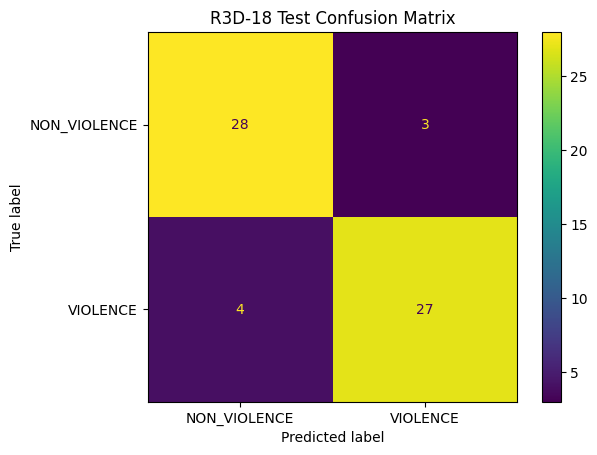

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("TEST ACCURACY:",
      accuracy_score(all_labels, all_predictions))

print("\nCLASSIFICATION REPORT:\n")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["NON_VIOLENCE", "VIOLENCE"],
        zero_division=0
    )
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NON_VIOLENCE", "VIOLENCE"]
)

disp.plot(values_format="d")
plt.title("R3D-18 Test Confusion Matrix")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Create prediction dataframe
results = test_df.reset_index(drop=True).copy()

results["actual"] = all_labels
results["predicted"] = all_predictions

# Aggregate predictions by source video
video_results = (
    results.groupby(["video_id", "label"])
    .agg(
        total_clips=("predicted", "count"),
        violence_predictions=("predicted", "sum"),
        violence_probability=("predicted", "mean")
    )
    .reset_index()
)

# Majority voting
video_results["video_prediction"] = (
    video_results["violence_predictions"] >
    video_results["total_clips"] / 2
).astype(int)

print("VIDEO-LEVEL RESULTS")
print(video_results)

print("\nVIDEO-LEVEL CLASSIFICATION REPORT")

print(classification_report(
    video_results["label"],
    video_results["video_prediction"],
    labels=[0, 1],
    target_names=["NON_VIOLENCE", "VIOLENCE"],
    zero_division=0
))

print("\nVIDEO-LEVEL CONFUSION MATRIX")

print(confusion_matrix(
    video_results["label"],
    video_results["video_prediction"],
    labels=[0, 1]
))

VIDEO-LEVEL RESULTS
                  video_id  label  total_clips  violence_predictions  \
0         Fighting003_x264      1            3                     3   
1         Fighting004_x264      1            3                     3   
2         Fighting005_x264      1            3                     3   
3         Fighting006_x264      1            3                     3   
4         Fighting007_x264      1            3                     3   
5         Fighting008_x264      1            3                     3   
6         Fighting009_x264      1            3                     3   
7         Fighting010_x264      1            1                     1   
8         Fighting011_x264      1            3                     2   
9         Fighting012_x264      1            3                     0   
10        Fighting013_x264      1            3                     3   
11  Normal_Videos_015_x264      0            3                     1   
12  Normal_Videos_050_x264      0           

In [ ]:
# ROLLING WINDOW VIOLENCE DETECTION
import torch
import torch.nn as nn
from torchvision.models.video import r3d_18

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint = torch.load(
    PROJECT / "model" / "r3d18_best.pth",
    map_location=device,
    weights_only=False
)

model = r3d_18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 2)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Best R3D-18 model loaded.")
print("Device:", device)
print("Best validation accuracy:", checkpoint["best_val_accuracy"])

Best R3D-18 model loaded.
Device: cuda
Best validation accuracy: 0.7916666666666666


In [ ]:
#Create the rolling-window inference function
import cv2
import numpy as np
import torch
from collections import deque

# Same normalization used during training
MEAN = torch.tensor(
    [0.43216, 0.394666, 0.37645]
).view(1, 3, 1, 1, 1).to(device)

STD = torch.tensor(
    [0.22803, 0.22145, 0.216989]
).view(1, 3, 1, 1, 1).to(device)


def predict_window(frames):

    # frames: list of 16 RGB frames
    video = np.stack(frames)

    # [T,H,W,C] -> [1,C,T,H,W]
    video = torch.from_numpy(video).permute(3, 0, 1, 2)
    video = video.unsqueeze(0).float().to(device) / 255.0

    video = (video - MEAN) / STD

    with torch.no_grad():
        outputs = model(video)
        probabilities = torch.softmax(outputs, dim=1)

    violence_probability = probabilities[0, 1].item()

    return violence_probability


def detect_violence_video(video_path, threshold=0.5):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        cap.release()
        raise RuntimeError("Invalid video FPS.")

    # Sample approximately 8 frames per second
    frame_step = max(1, round(fps / 8))

    frame_buffer = deque(maxlen=16)
    probability_buffer = deque(maxlen=3)

    frame_index = 0
    predictions = []

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame_index % frame_step == 0:

            frame = cv2.resize(frame, (112, 112))
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            frame_buffer.append(frame)

            # Predict when 16 frames are available
            if len(frame_buffer) == 16:

                probability = predict_window(list(frame_buffer))

                probability_buffer.append(probability)

                smoothed_probability = float(
                    np.mean(probability_buffer)
                )

                label = (
                    "VIOLENCE"
                    if smoothed_probability >= threshold
                    else "NON_VIOLENCE"
                )

                timestamp = frame_index / fps

                predictions.append({
                    "timestamp": round(timestamp, 2),
                    "violence_probability": round(probability, 4),
                    "smoothed_probability": round(
                        smoothed_probability, 4
                    ),
                    "prediction": label
                })

                print(
                    f"Time: {timestamp:.2f}s | "
                    f"Violence probability: {smoothed_probability:.3f} | "
                    f"Prediction: {label}"
                )

        frame_index += 1

    cap.release()

    return predictions

In [ ]:
test_video = FIGHTING_DIR / "Fighting003_x264.mp4"

predictions = detect_violence_video(test_video)

print("\nTotal prediction windows:", len(predictions))

if predictions:
    violence_count = sum(
        p["prediction"] == "VIOLENCE"
        for p in predictions
    )

    print("Violence windows:", violence_count)
    print(
        "Percentage of windows flagged:",
        round(100 * violence_count / len(predictions), 2),
        "%"
    )

Time: 2.00s | Violence probability: 0.745 | Prediction: VIOLENCE
Time: 2.13s | Violence probability: 0.740 | Prediction: VIOLENCE
Time: 2.27s | Violence probability: 0.733 | Prediction: VIOLENCE
Time: 2.40s | Violence probability: 0.728 | Prediction: VIOLENCE
Time: 2.53s | Violence probability: 0.725 | Prediction: VIOLENCE
Time: 2.67s | Violence probability: 0.721 | Prediction: VIOLENCE
Time: 2.80s | Violence probability: 0.725 | Prediction: VIOLENCE
Time: 2.93s | Violence probability: 0.742 | Prediction: VIOLENCE
Time: 3.07s | Violence probability: 0.777 | Prediction: VIOLENCE
Time: 3.20s | Violence probability: 0.793 | Prediction: VIOLENCE
Time: 3.33s | Violence probability: 0.793 | Prediction: VIOLENCE
Time: 3.47s | Violence probability: 0.769 | Prediction: VIOLENCE
Time: 3.60s | Violence probability: 0.745 | Prediction: VIOLENCE
Time: 3.73s | Violence probability: 0.715 | Prediction: VIOLENCE
Time: 3.87s | Violence probability: 0.711 | Prediction: VIOLENCE
Time: 4.00s | Violence pr

In [ ]:
#testing on a normal video
normal_test_video = NORMAL_DIR / "Normal_Videos_015_x264.mp4"

normal_predictions = detect_violence_video(normal_test_video)

print("\n========== NORMAL VIDEO RESULTS ==========")

total = len(normal_predictions)

violence_count = sum(
    p["prediction"] == "VIOLENCE"
    for p in normal_predictions
)

normal_count = total - violence_count

print("Total windows:", total)
print("Violence windows:", violence_count)
print("Normal windows:", normal_count)

if total > 0:
    print(
        "False alarm window percentage:",
        round(violence_count / total * 100, 2),
        "%"
    )

Time: 2.00s | Violence probability: 0.424 | Prediction: NON_VIOLENCE
Time: 2.13s | Violence probability: 0.424 | Prediction: NON_VIOLENCE
Time: 2.27s | Violence probability: 0.431 | Prediction: NON_VIOLENCE
Time: 2.40s | Violence probability: 0.430 | Prediction: NON_VIOLENCE
Time: 2.53s | Violence probability: 0.426 | Prediction: NON_VIOLENCE
Time: 2.67s | Violence probability: 0.409 | Prediction: NON_VIOLENCE
Time: 2.80s | Violence probability: 0.383 | Prediction: NON_VIOLENCE
Time: 2.93s | Violence probability: 0.351 | Prediction: NON_VIOLENCE
Time: 3.07s | Violence probability: 0.322 | Prediction: NON_VIOLENCE
Time: 3.20s | Violence probability: 0.308 | Prediction: NON_VIOLENCE
Time: 3.33s | Violence probability: 0.317 | Prediction: NON_VIOLENCE
Time: 3.47s | Violence probability: 0.331 | Prediction: NON_VIOLENCE
Time: 3.60s | Violence probability: 0.352 | Prediction: NON_VIOLENCE
Time: 3.73s | Violence probability: 0.357 | Prediction: NON_VIOLENCE
Time: 3.87s | Violence probability

In [ ]:
filename = "Normal_Videos_015_x264.mp4"

print(
    manifest[
        manifest["filename"] == filename
    ][["filename", "split", "category"]]
)

                      filename split             category
88  Normal_Videos_015_x264.mp4  test  Normal_Videos_event


In [ ]:
validation_videos = manifest[
    manifest["split"] == "validation"
]

print(
    validation_videos[
        ["original_video_id", "filename", "category"]
    ].to_string(index=False)
)

     original_video_id                   filename            category
      Fighting047_x264       Fighting047_x264.mp4            Fighting
      Fighting050_x264       Fighting050_x264.mp4            Fighting
      Fighting018_x264       Fighting018_x264.mp4            Fighting
      Fighting027_x264       Fighting027_x264.mp4            Fighting
      Fighting044_x264       Fighting044_x264.mp4            Fighting
      Fighting040_x264       Fighting040_x264.mp4            Fighting
      Fighting020_x264       Fighting020_x264.mp4            Fighting
      Fighting041_x264       Fighting041_x264.mp4            Fighting
Normal_Videos_905_x264 Normal_Videos_905_x264.mp4 Normal_Videos_event
Normal_Videos_914_x264 Normal_Videos_914_x264.mp4 Normal_Videos_event
Normal_Videos_365_x264 Normal_Videos_365_x264.mp4 Normal_Videos_event
Normal_Videos_603_x264 Normal_Videos_603_x264.mp4 Normal_Videos_event
Normal_Videos_881_x264 Normal_Videos_881_x264.mp4 Normal_Videos_event
Normal_Videos_801_x2

In [ ]:
# generating the pt file
import torch
from pathlib import Path

MODEL_DIR = PROJECT / "model"

checkpoint = torch.load(
    MODEL_DIR / "r3d18_best.pth",
    map_location="cpu",
    weights_only=False
)

pt_path = MODEL_DIR / "violence_detection_r3d18.pt"

torch.save({
    "model_state_dict": checkpoint["model_state_dict"],
    "model_name": "R3D-18",
    "num_classes": 2,
    "class_names": ["NON_VIOLENCE", "VIOLENCE"],
    "input_shape": [3, 16, 112, 112],
    "best_validation_accuracy": checkpoint["best_val_accuracy"],
    "best_epoch": checkpoint["epoch"]
}, pt_path)

print("Export successful!")
print("File:", pt_path)
print("Size:", round(pt_path.stat().st_size / (1024**2), 2), "MB")

Export successful!
File: /content/drive/MyDrive/Campus_Threat/model/violence_detection_r3d18.pt
Size: 126.6 MB
